In [1]:
import pandas as pd
import numpy as np

# Set random seed for reproducibility
np.random.seed(42)
n = 1500

# Generate raw synthetic data
data = {
    'order_id': [f'ORD-{i}' for i in range(1000, 1000 + n)],
    'customer_id': np.random.choice([f'CUST-{np.random.randint(100, 300)}' for _ in range(200)], size=n),
    'product_category': np.random.choice(['Electronics', 'Clothing', 'Home & Kitchen', 'Beauty', 'Sports', np.nan], size=n, p=[0.3, 0.25, 0.2, 0.1, 0.1, 0.05]),
    'unit_price': np.random.uniform(10.0, 500.0, size=n).round(2),
    'quantity': np.random.choice([1, 2, 3, 4, 5, np.nan], size=n, p=[0.5, 0.25, 0.12, 0.08, 0.03, 0.02]),
    'discount_percent': np.random.choice([0, 5, 10, 15, 20], size=n, p=[0.4, 0.3, 0.15, 0.1, 0.05]),
    'order_date': pd.date_range(start='2025-01-01', periods=n, freq='H').astype(str)
}

df = pd.DataFrame(data)

# Inject some duplicate rows intentionally for cleaning practice
df = pd.concat([df, df.sample(n=25, random_state=42)], ignore_index=True)

print(f"Initial dataset shape: {df.shape}")
df.head()

Initial dataset shape: (1525, 7)


C:\Users\Shreya\AppData\Local\Temp\ipykernel_4484\3418990608.py:16: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  'order_date': pd.date_range(start='2025-01-01', periods=n, freq='H').astype(str)


,order_id,customer_id,product_category,unit_price,quantity,discount_percent,order_date
0,ORD-1000,CUST-259,Electronics,253.38,1.0,5,2025-01-01 00:00:00
1,ORD-1001,CUST-253,Beauty,149.29,1.0,5,2025-01-01 01:00:00
2,ORD-1002,CUST-191,Clothing,75.58,1.0,10,2025-01-01 02:00:00
3,ORD-1003,CUST-235,Electronics,318.48,2.0,0,2025-01-01 03:00:00
4,ORD-1004,CUST-210,nan,36.62,1.0,0,2025-01-01 04:00:00


In [2]:
# 1. Remove duplicate rows
initial_rows = len(df)
df = df.drop_duplicates()
print(f"Removed {initial_rows - len(df)} duplicate rows.")

# 2. Handle missing values
# Fill missing product category with 'Unknown'
df['product_category'] = df['product_category'].fillna('Unknown')

# Fill missing quantities with the median quantity
median_qty = df['quantity'].median()
df['quantity'] = df['quantity'].fillna(median_qty)

# 3. Fix data types
df['order_date'] = pd.to_datetime(df['order_date'])
df['quantity'] = df['quantity'].astype(int)

# Verify cleaning results
print("Missing values after cleaning:\n", df.isnull().sum())

Removed 25 duplicate rows.
Missing values after cleaning:
 order_id            0
customer_id         0
product_category    0
unit_price          0
quantity            0
discount_percent    0
order_date          0
dtype: int64


In [3]:
# 1. Calculate Gross and Net Total Sales
df['gross_sales'] = df['unit_price'] * df['quantity']
df['discount_amount'] = df['gross_sales'] * (df['discount_percent'] / 100)
df['net_sales'] = (df['gross_sales'] - df['discount_amount']).round(2)

# 2. Extract date features for trend analysis
df['order_year_month'] = df['order_date'].dt.to_period('M')
df['day_of_week'] = df['order_date'].dt.day_name()
df['hour_of_day'] = df['order_date'].dt.hour

# 3. Customer Segmentation (High Value vs Standard based on total spend)
customer_spend = df.groupby('customer_id')['net_sales'].sum().reset_index()
high_value_threshold = customer_spend['net_sales'].quantile(0.75)
high_value_customers = customer_spend[customer_spend['net_sales'] >= high_value_threshold]['customer_id']

df['customer_segment'] = df['customer_id'].apply(lambda x: 'VIP' if x in high_value_customers else 'Regular')

df.head()

,order_id,customer_id,product_category,unit_price,quantity,discount_percent,order_date,gross_sales,discount_amount,net_sales,order_year_month,day_of_week,hour_of_day,customer_segment
0,ORD-1000,CUST-259,Electronics,253.38,1,5,2025-01-01 00:00:00,253.38,12.6690,240.71,2025-01,Wednesday,0,Regular
1,ORD-1001,CUST-253,Beauty,149.29,1,5,2025-01-01 01:00:00,149.29,7.4645,141.83,2025-01,Wednesday,1,Regular
2,ORD-1002,CUST-191,Clothing,75.58,1,10,2025-01-01 02:00:00,75.58,7.5580,68.02,2025-01,Wednesday,2,Regular
3,ORD-1003,CUST-235,Electronics,318.48,2,0,2025-01-01 03:00:00,636.96,0.0000,636.96,2025-01,Wednesday,3,Regular
4,ORD-1004,CUST-210,nan,36.62,1,0,2025-01-01 04:00:00,36.62,0.0000,36.62,2025-01,Wednesday,4,Regular


In [4]:
# 1. Total Revenue by Product Category
category_performance = df.groupby('product_category').agg(
    total_revenue=('net_sales', 'sum'),
    total_orders=('order_id', 'count'),
    avg_order_value=('net_sales', 'mean')
).sort_values(by='total_revenue', ascending=False)

print("Category Performance Summary:")
print(category_performance)

# 2. Monthly Sales Trend
monthly_trend = df.groupby('order_year_month')['net_sales'].sum().reset_index()
print("\nMonthly Sales Trend:")
print(monthly_trend)

Category Performance Summary:
                  total_revenue  total_orders  avg_order_value
product_category                                              
Electronics           185398.36           442       419.453303
Clothing              169219.65           368       459.836005
Home & Kitchen        140578.33           311       452.020354
Beauty                 68020.94           156       436.031667
Sports                 64916.15           139       467.022662
nan                    34589.21            84       411.776310

Monthly Sales Trend:
  order_year_month  net_sales
0          2025-01  327431.50
1          2025-02  292002.20
2          2025-03   43288.94


C:\Users\Shreya\AppData\Local\Temp\ipykernel_4484\490238859.py:10: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='product_category', y='net_sales', estimator=sum, ci=None, palette='viridis')
C:\Users\Shreya\AppData\Local\Temp\ipykernel_4484\490238859.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='product_category', y='net_sales', estimator=sum, ci=None, palette='viridis')
C:\Users\Shreya\AppData\Local\Temp\ipykernel_4484\490238859.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='day_of_week', order=day_order, palette='crest')


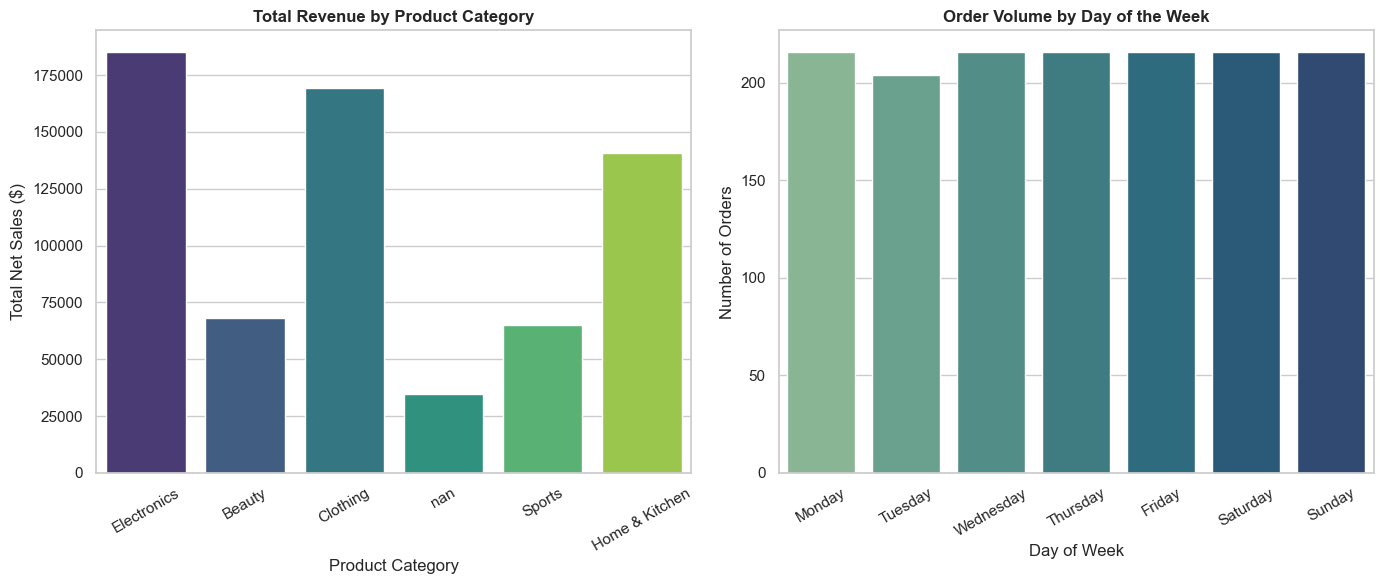

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 6))

# Plot 1: Revenue by Product Category
plt.subplot(1, 2, 1)
sns.barplot(data=df, x='product_category', y='net_sales', estimator=sum, ci=None, palette='viridis')
plt.title('Total Revenue by Product Category', fontsize=12, fontweight='bold')
plt.xlabel('Product Category')
plt.ylabel('Total Net Sales ($)')
plt.xticks(rotation=30)

# Plot 2: Sales Distribution Across Days of the Week
plt.subplot(1, 2, 2)
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
sns.countplot(data=df, x='day_of_week', order=day_order, palette='crest')
plt.title('Order Volume by Day of the Week', fontsize=12, fontweight='bold')
plt.xlabel('Day of Week')
plt.ylabel('Number of Orders')
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()